In [32]:
# ENTROPY_TQGUESS_UAGRAD_PROFILE_TRIAL
# Single-trial run for the entropy-enabled compact BVP solver
# with downstream T_Q treated as a global unknown and
# 0 = d_x(s*u) + (nB_Q/T)*muK*d_x(u*a).

import numpy as np

import RMFsolver.constants as const
from RMFsolver.phase_velocity import _solve_scalar_root, nB_NM
from RMFsolver.phase_velocity import _solve_scalar_root, nB_NM
from RMFsolver.phase_velocity import solve_front_adiabatic

# -------------------------
# Entropy-TQguess u*a-gradient trial inputs
# -------------------------
T_entropy_tq_uagrad_trial = 5
n0 = 0.16 * const.MeV_fm**3
nB_N_entropy_tq_uagrad_trial = 3.0 * n0
B14_entropy_tq_uagrad_trial = 180.0
ms_entropy_tq_uagrad_trial = 0.0

aQstar_entropy_tq_uagrad_trial = 0.3
tail_eps_entropy_tq_uagrad_trial = 1.0e-6

# Entropy-TQguess u*a-gradient solve.
n_mesh_entropy_tq_uagrad_trial = 80
tol_entropy_tq_uagrad_trial = 1.0e-6
max_nodes_entropy_tq_uagrad_trial = 3000
jB_bounds_entropy_tq_uagrad_trial = (1.0e-5, 5.0)
TQ_guess_entropy_tq_uagrad_trial = T_entropy_tq_uagrad_trial + 50
verb_entropy_tq_uagrad_trial = False

# -------------------------
# Run the entropy-TQguess u*a-gradient solver
# -------------------------
res_entropy_tq_uagrad_trial = solve_front_adiabatic(
    T=T_entropy_tq_uagrad_trial,
    nB_N=nB_N_entropy_tq_uagrad_trial,
    B_one_forth=B14_entropy_tq_uagrad_trial,
    aQstar=aQstar_entropy_tq_uagrad_trial,
    ms=ms_entropy_tq_uagrad_trial,
    tail_eps=tail_eps_entropy_tq_uagrad_trial,
    n_mesh=n_mesh_entropy_tq_uagrad_trial,
    tol_bvp=tol_entropy_tq_uagrad_trial,
    max_nodes=max_nodes_entropy_tq_uagrad_trial,
    jB_guess=None,
    TQ_guess=TQ_guess_entropy_tq_uagrad_trial,
    jB_bounds=jB_bounds_entropy_tq_uagrad_trial,
    return_profile=True,
    verb=verb_entropy_tq_uagrad_trial,
)

required_entropy_tq_uagrad_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_tq_uagrad_profile_keys = [
    key for key in required_entropy_tq_uagrad_profile_keys if key not in res_entropy_tq_uagrad_trial
]
if missing_entropy_tq_uagrad_profile_keys:
    raise RuntimeError(
        'Entropy-TQguess u*a-gradient trial is missing profile arrays: '
        + ', '.join(missing_entropy_tq_uagrad_profile_keys)
    )

x_end_nm_entropy_tq_uagrad_trial = float(
    np.max(np.asarray(res_entropy_tq_uagrad_trial['x'], dtype=float)) * const.MeV_fm / 1.0e6
)
T_prof_entropy_tq_uagrad_trial = np.asarray(res_entropy_tq_uagrad_trial['T_profile'], dtype=float)
nB_prof_entropy_tq_uagrad_trial = np.asarray(res_entropy_tq_uagrad_trial['nB'], dtype=float) / n0

print('Entropy-TQguess u*a-gradient solve:')
print(f"  success: {res_entropy_tq_uagrad_trial.get('success')}")
print(f"  message: {res_entropy_tq_uagrad_trial.get('message', '')}")
print(f"  entropy_flux_equation: {res_entropy_tq_uagrad_trial.get('entropy_flux_equation', '')}")
print(f"  bvp_status: {res_entropy_tq_uagrad_trial.get('bvp_status', np.nan)}")
print(f"  bvp_message: {res_entropy_tq_uagrad_trial.get('bvp_message', '')}")
print(f"  bvp_niter: {res_entropy_tq_uagrad_trial.get('bvp_niter', np.nan)}")
print(f"  bvp_nodes: {res_entropy_tq_uagrad_trial.get('bvp_nodes', np.nan)}")
print(f"  jB: {res_entropy_tq_uagrad_trial.get('jB', np.nan):.8g}")
print(f"  T_Q: {res_entropy_tq_uagrad_trial.get('T_Q', np.nan):.8g} MeV")
print(f"  w_Q: {res_entropy_tq_uagrad_trial.get('w_Q', np.nan):.8g}")
print(f"  tail_norm: {res_entropy_tq_uagrad_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  entropy_tail_norm: {res_entropy_tq_uagrad_trial.get('entropy_tail_residual_norm', np.nan):.8g}")
print(f"  muB_Q: {res_entropy_tq_uagrad_trial.get('muB_Q', np.nan):.8g} MeV")
print(f"  muK_Qstar: {res_entropy_tq_uagrad_trial.get('muK_Qstar', np.nan):.8g} MeV")
print(f"  x_end: {x_end_nm_entropy_tq_uagrad_trial:.6g} nm")
print(
    f"  T range: [{np.min(T_prof_entropy_tq_uagrad_trial):.6g}, "
    f"{np.max(T_prof_entropy_tq_uagrad_trial):.6g}] MeV"
)
print(
    f"  nB/n0 range: [{np.min(nB_prof_entropy_tq_uagrad_trial):.6g}, "
    f"{np.max(nB_prof_entropy_tq_uagrad_trial):.6g}]"
)


Entropy-TQguess u*a-gradient solve:
  success: True
  message: Adiabatic compact BVP steady-front solve converged
  entropy_flux_equation: ua_gradient
  bvp_status: 0
  bvp_message: The algorithm converged to the desired accuracy.
  bvp_niter: 2
  bvp_nodes: 238
  jB: 0.6583987
  T_Q: 18.044189 MeV
  w_Q: 0.91461747
  tail_norm: -1.5278175e-11
  entropy_tail_norm: -4.9141058e-11
  muB_Q: 1140.4095 MeV
  muK_Qstar: 77.416979 MeV
  x_end: 2545.54 nm
  T range: [5, 18.0442] MeV
  nB/n0 range: [4.62798, 4.62798]


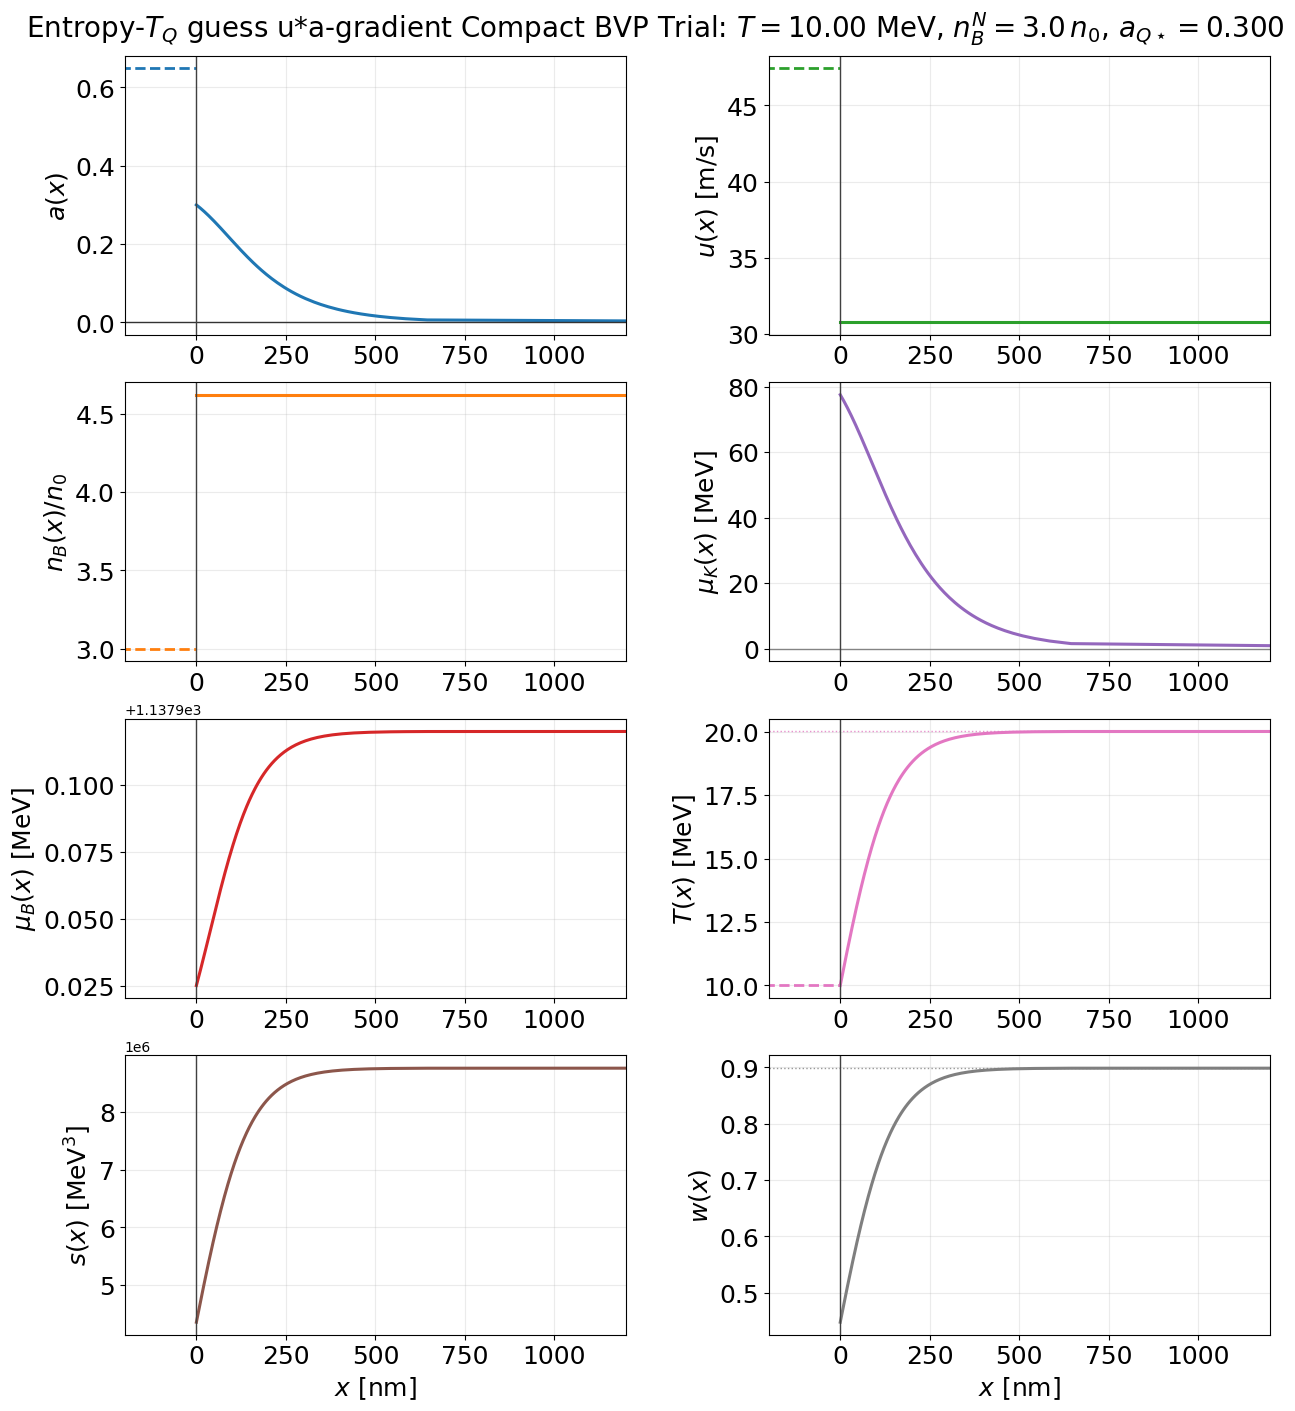

In [7]:
# VISUALIZE_ENTROPY_TQGUESS_UAGRAD_PROFILE_TRIAL
# Visualize the entropy-TQguess u*a-gradient single-trial result.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import _solve_scalar_root, nB_NM

required_entropy_tq_uagrad_trial_names = [
    'res_entropy_tq_uagrad_trial',
    'T_entropy_tq_uagrad_trial',
    'nB_N_entropy_tq_uagrad_trial',
    'aQstar_entropy_tq_uagrad_trial',
    'n0',
]
missing_entropy_tq_uagrad_trial_names = [
    name for name in required_entropy_tq_uagrad_trial_names if name not in globals()
]
if missing_entropy_tq_uagrad_trial_names:
    raise RuntimeError(
        'Run the ENTROPY_TQGUESS_UAGRAD_PROFILE_TRIAL cell first. Missing names: '
        + ', '.join(missing_entropy_tq_uagrad_trial_names)
    )

required_entropy_tq_uagrad_profile_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'w', 'T_profile', 's_profile'
]
missing_entropy_tq_uagrad_profile_keys = [
    key for key in required_entropy_tq_uagrad_profile_keys if key not in res_entropy_tq_uagrad_trial
]
if missing_entropy_tq_uagrad_profile_keys:
    raise RuntimeError(
        'Entropy-TQguess u*a-gradient trial is missing profile arrays: '
        + ', '.join(missing_entropy_tq_uagrad_profile_keys)
    )

x_nm = np.asarray(res_entropy_tq_uagrad_trial['x'], dtype=float) * const.MeV_fm / 1.0e6
a_prof = np.asarray(res_entropy_tq_uagrad_trial['a'], dtype=float)
u_ms = np.asarray(res_entropy_tq_uagrad_trial['u'], dtype=float) * const.m_per_sec
muK_prof = np.asarray(res_entropy_tq_uagrad_trial['muK'], dtype=float)
muB_prof = np.asarray(res_entropy_tq_uagrad_trial['muB'], dtype=float)
nB_prof_over_n0 = np.asarray(res_entropy_tq_uagrad_trial['nB'], dtype=float) / n0
T_prof = np.asarray(res_entropy_tq_uagrad_trial['T_profile'], dtype=float)
s_prof = np.asarray(res_entropy_tq_uagrad_trial['s_profile'], dtype=float)
w_prof = np.asarray(res_entropy_tq_uagrad_trial['w'], dtype=float)

positive_extent_nm = float(np.nanmax(x_nm)) if len(x_nm) else 1.0
positive_extent_nm = max(positive_extent_nm, 1.0e-3)
left_extent_nm = max(0.12 * positive_extent_nm, 500.0)
x_left_nm = np.linspace(-left_extent_nm, 0.0, 120)
a_left = np.full_like(x_left_nm, float(res_entropy_tq_uagrad_trial.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(
    x_left_nm,
    float(res_entropy_tq_uagrad_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
nB_left_over_n0 = np.full_like(x_left_nm, float(nB_N_entropy_tq_uagrad_trial / n0), dtype=float)
T_left = np.full_like(x_left_nm, float(T_entropy_tq_uagrad_trial), dtype=float)

TitleFont = 20
LabelFont = 18
TickFont = 18
LegendFont = 18

fig, axes = plt.subplots(4, 2, figsize=(13.0, 14.0), constrained_layout=True)

axes[0, 0].plot(x_left_nm, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0, 0].plot(x_nm, a_prof, lw=2.2, color='C0', label=r'$x>0$: entropy-TQguess u*a-gradient profile')
axes[0, 0].axhline(0.0, color='0.20', lw=1.0)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)

axes[0, 1].plot(x_left_nm, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[0, 1].plot(x_nm, u_ms, lw=2.2, color='C2', label=r'$x>0$: entropy-TQguess u*a-gradient profile')
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)

axes[1, 0].plot(x_left_nm, nB_left_over_n0, lw=2.0, ls='--', color='C1', label=r'$x<0$: upstream $n_B/n_0$')
axes[1, 0].plot(x_nm, nB_prof_over_n0, lw=2.2, color='C1', label=r'$x>0$: entropy-TQguess u*a-gradient profile')
axes[1, 0].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)

axes[1, 1].plot(x_nm, muK_prof, lw=2.2, color='C4')
axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

axes[2, 0].plot(x_nm, muB_prof, lw=2.2, color='C3')
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)

axes[2, 1].plot(x_left_nm, T_left, lw=2.0, ls='--', color='C6', label=r'$x<0$: upstream $T$')
axes[2, 1].plot(x_nm, T_prof, lw=2.2, color='C6', label=r'$x>0$: reconstructed $T(x)$')
axes[2, 1].axhline(float(res_entropy_tq_uagrad_trial.get('T_Q', np.nan)), color='C6', lw=1.0, ls=':', alpha=0.8, label=r'$T_Q$')
axes[2, 1].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)

axes[3, 0].plot(x_nm, s_prof, lw=2.2, color='C5')
axes[3, 0].set_ylabel(r'$s(x)$ [MeV$^3$]', fontsize=LabelFont)
axes[3, 0].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

axes[3, 1].plot(x_nm, w_prof, lw=2.2, color='C7', label=r'$w(x)=s(x)u(x)$')
axes[3, 1].axhline(float(res_entropy_tq_uagrad_trial.get('w_Q', np.nan)), color='C7', lw=1.0, ls=':', alpha=0.8, label=r'$w_Q$')
axes[3, 1].set_ylabel(r'$w(x)$', fontsize=LabelFont)
axes[3, 1].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

for ax in axes.flat:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(-200, 1200)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig.suptitle(
    rf'Entropy-$T_Q$ guess u*a-gradient Compact BVP Trial: $T={T_entropy_tq_uagrad_trial:.2f}$ MeV, '
    rf'$n_{{B}}^{{N}}={nB_N_entropy_tq_uagrad_trial / n0:.1f}\,n_0$, '
    rf'$a_{{Q\star}}={aQstar_entropy_tq_uagrad_trial:.3f}$',
    fontsize=TitleFont,
)

plt.show()


In [1]:
# ISOTHERMAL_PROFILE_TRIAL
# Single-trial run for the compact BVP isothermal solver.

import numpy as np

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_front_isothermal

# -------------------------
# Isothermal trial inputs
# -------------------------
T_isothermal_trial = 0.1
n0 = 0.16 * const.MeV_fm**3
nB_N_isothermal_trial = 3.0 * n0
B14_isothermal_trial = 180.0
ms_isothermal_trial = 0.0

aQstar_isothermal_trial = 0.3
tail_eps_isothermal_trial = 1.0e-6

# Isothermal solve.
n_mesh_isothermal_trial = 80
tol_isothermal_trial = 1.0e-6
max_nodes_isothermal_trial = 3000
jB_guess_isothermal_trial = 0.5
jB_bounds_isothermal_trial = (1.0e-4, 5.0)
kappa_factor_isothermal_trial = 1.0
verb_isothermal_trial = False

# -------------------------
# Run the isothermal solver
# -------------------------
res_isothermal_trial = solve_front_isothermal(
    T=T_isothermal_trial,
    nB_N=nB_N_isothermal_trial,
    B_one_forth=B14_isothermal_trial,
    aQstar=aQstar_isothermal_trial,
    ms=ms_isothermal_trial,
    tail_eps=tail_eps_isothermal_trial,
    n_mesh=n_mesh_isothermal_trial,
    tol_bvp=tol_isothermal_trial,
    max_nodes=max_nodes_isothermal_trial,
    jB_guess=jB_guess_isothermal_trial,
    jB_bounds=jB_bounds_isothermal_trial,
    kappa_factor=kappa_factor_isothermal_trial,
    return_profile=True,
    verb=verb_isothermal_trial,
)

required_isothermal_profile_keys = [
    'x', 'a', 'q', 'u', 'muK', 'muB', 'nB'
]
missing_isothermal_profile_keys = [
    key for key in required_isothermal_profile_keys if key not in res_isothermal_trial
]
if missing_isothermal_profile_keys:
    raise RuntimeError(
        'Isothermal trial is missing profile arrays: '
        + ', '.join(missing_isothermal_profile_keys)
    )

x_end_nm_isothermal_trial = float(
    np.max(np.asarray(res_isothermal_trial['x'], dtype=float)) * const.MeV_fm / 1.0e6
)
nB_prof_isothermal_trial = np.asarray(res_isothermal_trial['nB'], dtype=float) / n0
closure_prof_isothermal_trial = np.asarray(res_isothermal_trial.get('closure_error', np.nan), dtype=float)

print('Isothermal solve:')
print(f"  success: {res_isothermal_trial.get('success')}")
print(f"  message: {res_isothermal_trial.get('message', '')}")
print(f"  bvp_status: {res_isothermal_trial.get('bvp_status', np.nan)}")
print(f"  bvp_message: {res_isothermal_trial.get('bvp_message', '')}")
print(f"  bvp_niter: {res_isothermal_trial.get('bvp_niter', np.nan)}")
print(f"  bvp_nodes: {res_isothermal_trial.get('bvp_nodes', np.nan)}")
print(f"  jB: {res_isothermal_trial.get('jB', np.nan):.8g}")
print(f"  retry_source: {res_isothermal_trial.get('retry_source', '')}")
print(f"  retry_seed_jB: {res_isothermal_trial.get('retry_seed_jB', np.nan):.8g}")
print(f"  u_Q: {res_isothermal_trial.get('u_Q', np.nan):.8g}")
print(f"  tail_norm: {res_isothermal_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  muB_Q: {res_isothermal_trial.get('muB_Q', np.nan):.8g} MeV")
print(f"  muK_Qstar: {res_isothermal_trial.get('muK_Qstar', np.nan):.8g} MeV")
print(f"  D: {res_isothermal_trial.get('D', np.nan):.8g}")
print(f"  eta: {res_isothermal_trial.get('eta', np.nan):.8g}")
print(f"  gamma: {res_isothermal_trial.get('gamma', np.nan):.8g}")
print(f"  x_end: {x_end_nm_isothermal_trial:.6g} nm")
print(
    f"  nB/n0 range: [{np.min(nB_prof_isothermal_trial):.6g}, "
    f"{np.max(nB_prof_isothermal_trial):.6g}]"
)
if np.all(np.isfinite(closure_prof_isothermal_trial)):
    print(
        f"  closure error range: [{np.min(closure_prof_isothermal_trial):.6g}, "
        f"{np.max(closure_prof_isothermal_trial):.6g}]"
    )


Isothermal solve:
  success: False
  message: A singular Jacobian encountered when solving the collocation system.; last failure: 
  bvp_status: 2
  bvp_message: A singular Jacobian encountered when solving the collocation system.
  bvp_niter: 1
  bvp_nodes: 80
  jB: 0.0001
  retry_source: 
  retry_seed_jB: nan
  u_Q: 1.7394936e-11
  tail_norm: 0.060357102
  muB_Q: 1152.781 MeV
  muK_Qstar: 78.186915 MeV
  D: 1475.4271
  eta: 6.1418131e-06
  gamma: 1.6532658e-12
  x_end: 3.28642e+07 nm
  nB/n0 range: [4.62777, 4.67625]
  closure error range: [0, 7.46757e-11]


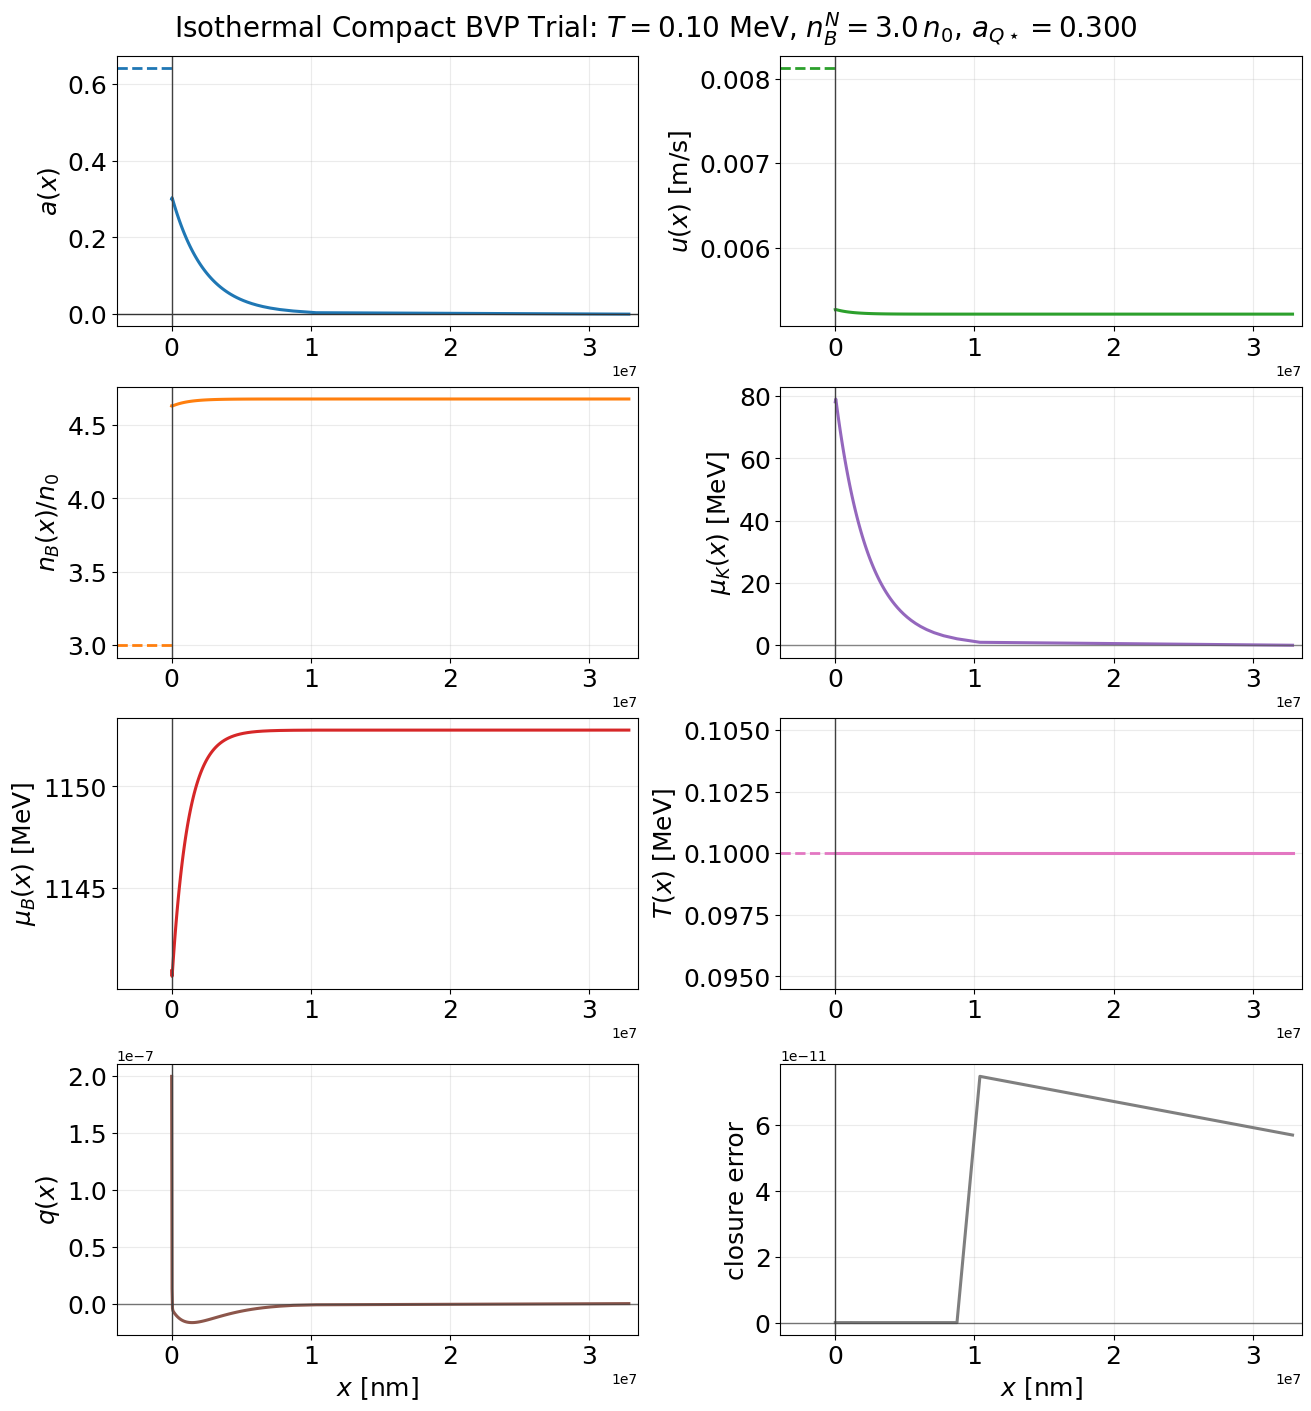

In [2]:
# VISUALIZE_ISOTHERMAL_PROFILE_TRIAL
# Visualize the isothermal single-trial result.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const

required_isothermal_trial_names = [
    'res_isothermal_trial',
    'T_isothermal_trial',
    'nB_N_isothermal_trial',
    'aQstar_isothermal_trial',
    'n0',
]
missing_isothermal_trial_names = [
    name for name in required_isothermal_trial_names if name not in globals()
]
if missing_isothermal_trial_names:
    raise RuntimeError(
        'Run the ISOTHERMAL_PROFILE_TRIAL cell first. Missing names: '
        + ', '.join(missing_isothermal_trial_names)
    )

required_isothermal_profile_keys = [
    'x', 'a', 'q', 'u', 'muK', 'muB', 'nB'
]
missing_isothermal_profile_keys = [
    key for key in required_isothermal_profile_keys if key not in res_isothermal_trial
]
if missing_isothermal_profile_keys:
    raise RuntimeError(
        'Isothermal trial is missing profile arrays: '
        + ', '.join(missing_isothermal_profile_keys)
    )

x_nm = np.asarray(res_isothermal_trial['x'], dtype=float) * const.MeV_fm / 1.0e6
a_prof = np.asarray(res_isothermal_trial['a'], dtype=float)
q_prof = np.asarray(res_isothermal_trial['q'], dtype=float)
u_ms = np.asarray(res_isothermal_trial['u'], dtype=float) * const.m_per_sec
muK_prof = np.asarray(res_isothermal_trial['muK'], dtype=float)
muB_prof = np.asarray(res_isothermal_trial['muB'], dtype=float)
nB_prof_over_n0 = np.asarray(res_isothermal_trial['nB'], dtype=float) / n0
closure_prof = np.asarray(res_isothermal_trial.get('closure_error', np.nan), dtype=float)
T_prof = np.full_like(x_nm, float(T_isothermal_trial), dtype=float)

positive_extent_nm = float(np.nanmax(x_nm)) if len(x_nm) else 1.0
positive_extent_nm = max(positive_extent_nm, 1.0e-3)
left_extent_nm = max(0.12 * positive_extent_nm, 500.0)
x_left_nm = np.linspace(-left_extent_nm, 0.0, 120)
a_left = np.full_like(x_left_nm, float(res_isothermal_trial.get('a_N', np.nan)), dtype=float)
u_left_ms = np.full_like(
    x_left_nm,
    float(res_isothermal_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
nB_left_over_n0 = np.full_like(x_left_nm, float(nB_N_isothermal_trial / n0), dtype=float)
T_left = np.full_like(x_left_nm, float(T_isothermal_trial), dtype=float)
x_right_limit_nm = max(1.02 * positive_extent_nm, 500.0)
x_left_limit_nm = -min(left_extent_nm, 0.2 * x_right_limit_nm)

TitleFont = 20
LabelFont = 18
TickFont = 18

fig, axes = plt.subplots(4, 2, figsize=(13.0, 14.0), constrained_layout=True)

axes[0, 0].plot(x_left_nm, a_left, lw=2.0, ls='--', color='C0', label=r'$x<0$: upstream $a_N$')
axes[0, 0].plot(x_nm, a_prof, lw=2.2, color='C0', label=r'$x>0$: isothermal profile')
axes[0, 0].axhline(0.0, color='0.20', lw=1.0)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)

axes[0, 1].plot(x_left_nm, u_left_ms, lw=2.0, ls='--', color='C2', label=r'$x<0$: upstream $u_N$')
axes[0, 1].plot(x_nm, u_ms, lw=2.2, color='C2', label=r'$x>0$: isothermal profile')
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)

axes[1, 0].plot(x_left_nm, nB_left_over_n0, lw=2.0, ls='--', color='C1', label=r'$x<0$: upstream $n_B/n_0$')
axes[1, 0].plot(x_nm, nB_prof_over_n0, lw=2.2, color='C1', label=r'$x>0$: isothermal profile')
axes[1, 0].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)

axes[1, 1].plot(x_nm, muK_prof, lw=2.2, color='C4')
axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)

axes[2, 0].plot(x_nm, muB_prof, lw=2.2, color='C3')
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)

axes[2, 1].plot(x_left_nm, T_left, lw=2.0, ls='--', color='C6', label=r'$x<0$: upstream $T$')
axes[2, 1].plot(x_nm, T_prof, lw=2.2, color='C6', label=r'$x>0$: isothermal $T(x)$')
axes[2, 1].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)

axes[3, 0].plot(x_nm, q_prof, lw=2.2, color='C5')
axes[3, 0].axhline(0.0, color='0.25', lw=1.0, alpha=0.7)
axes[3, 0].set_ylabel(r'$q(x)$', fontsize=LabelFont)
axes[3, 0].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

axes[3, 1].plot(x_nm, closure_prof, lw=2.2, color='C7')
axes[3, 1].axhline(0.0, color='0.25', lw=1.0, alpha=0.7)
axes[3, 1].set_ylabel(r'closure error', fontsize=LabelFont)
axes[3, 1].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

for ax in axes.flat:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(x_left_limit_nm, x_right_limit_nm)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig.suptitle(
    rf'Isothermal Compact BVP Trial: $T={T_isothermal_trial:.2f}$ MeV, '
    rf'$n_{{B}}^{{N}}={nB_N_isothermal_trial / n0:.1f}\,n_0$, '
    rf'$a_{{Q\star}}={aQstar_isothermal_trial:.3f}$',
    fontsize=TitleFont,
)

plt.show()


In [1]:
# COMPARE_ISOTHERMAL_ADIABATIC_TRIAL
# Run the isothermal and adiabatic solvers on the same input.

import numpy as np

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_front_adiabatic, solve_front_isothermal

# -------------------------
# Shared comparison inputs
# -------------------------
T_compare_trial = 10
n0 = 0.16 * const.MeV_fm**3
nB_N_compare_trial = 3.0 * n0
B14_compare_trial = 180.0
ms_compare_trial = 0.0

aQstar_compare_trial = 0.3
tail_eps_compare_trial = 1.0e-6

n_mesh_compare_trial = 80
tol_compare_trial = 1.0e-6
max_nodes_compare_trial = 3000
jB_guess_compare_trial = 0.5
jB_bounds_compare_trial = (1.0e-4, 5.0)
kappa_factor_compare_trial = 1.0
TQ_guess_compare_trial = 60
verb_compare_trial = False

# -------------------------
# Run both solvers
# -------------------------
res_isothermal_compare_trial = solve_front_isothermal(
    T=T_compare_trial,
    nB_N=nB_N_compare_trial,
    B_one_forth=B14_compare_trial,
    aQstar=aQstar_compare_trial,
    ms=ms_compare_trial,
    tail_eps=tail_eps_compare_trial,
    n_mesh=n_mesh_compare_trial,
    tol_bvp=tol_compare_trial,
    max_nodes=max_nodes_compare_trial,
    jB_guess=jB_guess_compare_trial,
    jB_bounds=jB_bounds_compare_trial,
    return_profile=True,
    verb=verb_compare_trial,
)

res_adiabatic_compare_trial = solve_front_adiabatic(
    T=T_compare_trial,
    nB_N=nB_N_compare_trial,
    B_one_forth=B14_compare_trial,
    aQstar=aQstar_compare_trial,
    ms=ms_compare_trial,
    tail_eps=tail_eps_compare_trial,
    n_mesh=n_mesh_compare_trial,
    tol_bvp=tol_compare_trial,
    max_nodes=max_nodes_compare_trial,
    jB_guess=jB_guess_compare_trial,
    TQ_guess=TQ_guess_compare_trial,
    jB_bounds=jB_bounds_compare_trial,
    #kappa_factor=kappa_factor_compare_trial,
    return_profile=True,
    verb=verb_compare_trial,
)

required_isothermal_compare_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB'
]
missing_isothermal_compare_keys = [
    key for key in required_isothermal_compare_keys if key not in res_isothermal_compare_trial
]
if missing_isothermal_compare_keys:
    raise RuntimeError(
        'Isothermal comparison trial is missing profile arrays: '
        + ', '.join(missing_isothermal_compare_keys)
    )

required_adiabatic_compare_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'T_profile', 'w', 's_profile'
]
missing_adiabatic_compare_keys = [
    key for key in required_adiabatic_compare_keys if key not in res_adiabatic_compare_trial
]
if missing_adiabatic_compare_keys:
    raise RuntimeError(
        'Adiabatic comparison trial is missing profile arrays: '
        + ', '.join(missing_adiabatic_compare_keys)
    )

print('Shared-input isothermal vs adiabatic comparison:')
print(f'  T = {T_compare_trial:.6g} MeV')
print(f'  nB_N/n0 = {nB_N_compare_trial / n0:.6g}')
print(f'  aQstar = {aQstar_compare_trial:.6g}')
print('')
print('Isothermal solve:')
print(f"  success: {res_isothermal_compare_trial.get('success')}")
print(f"  message: {res_isothermal_compare_trial.get('message', '')}")
print(f"  jB: {res_isothermal_compare_trial.get('jB', np.nan):.8g}")
print(f"  tail_norm: {res_isothermal_compare_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  retry_source: {res_isothermal_compare_trial.get('retry_source', '')}")
print('')
print('Adiabatic solve:')
print(f"  success: {res_adiabatic_compare_trial.get('success')}")
print(f"  message: {res_adiabatic_compare_trial.get('message', '')}")
print(f"  jB: {res_adiabatic_compare_trial.get('jB', np.nan):.8g}")
print(f"  T_Q: {res_adiabatic_compare_trial.get('T_Q', np.nan):.8g} MeV")
print(f"  tail_norm: {res_adiabatic_compare_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  entropy_tail_norm: {res_adiabatic_compare_trial.get('entropy_tail_residual_norm', np.nan):.8g}")


Shared-input isothermal vs adiabatic comparison:
  T = 10 MeV
  nB_N/n0 = 3
  aQstar = 0.3

Isothermal solve:
  success: True
  message: Compact BVP steady-front solve converged
  jB: 0.62947083
  tail_norm: 5.6129982e-07
  retry_source: 

Adiabatic solve:
  success: True
  message: Adiabatic compact BVP steady-front solve converged
  jB: 0.51088974
  T_Q: 32.228756 MeV
  tail_norm: 1.0815474e-14
  entropy_tail_norm: -3.861755e-15


In [4]:
uN_isothermal = res_isothermal_compare_trial["u_N"]
jB_isothermal = res_isothermal_compare_trial["jB"]
uN_adiabatic = res_adiabatic_compare_trial["u_N"]
jB_adiabatic = res_adiabatic_compare_trial["jB"]

u_isothermal = res_isothermal_compare_trial["u"]
u_adiabatic = res_adiabatic_compare_trial["u"]
x_adiabatic = res_adiabatic_compare_trial["x"]

s_profile = res_adiabatic_compare_trial["s_profile"]
w_profile = res_adiabatic_compare_trial["w"]

jB_isothermal/uN_isothermal, jB_adiabatic/uN_adiabatic

(3688081.5294971233, 3688081.529497124)

In [1]:
(max(u_adiabatic) - min(u_adiabatic))/np.mean(u_adiabatic)

NameError: name 'u_adiabatic' is not defined

In [47]:
max(w_profile /(u_adiabatic * s_profile)), min(w_profile /(u_adiabatic * s_profile))

(np.float64(1.0000000000001432), np.float64(0.9999999999997932))

In [35]:
uN_isothermal*3e8, type(res_isothermal_compare_trial["u_N"])

(72.8837347817847, float)

In [49]:
uN_isothermal*3e8/(u_isothermal[0]*3e8), uN_adiabatic*3e8/(u_adiabatic[-1]*3e8)

(np.float64(1.542345200210549), np.float64(1.5426610563658913))

isothermal q range: [-1.09672e-07, -7.15544e-14]
adiabatic w range: [1.06384, 1.26496]


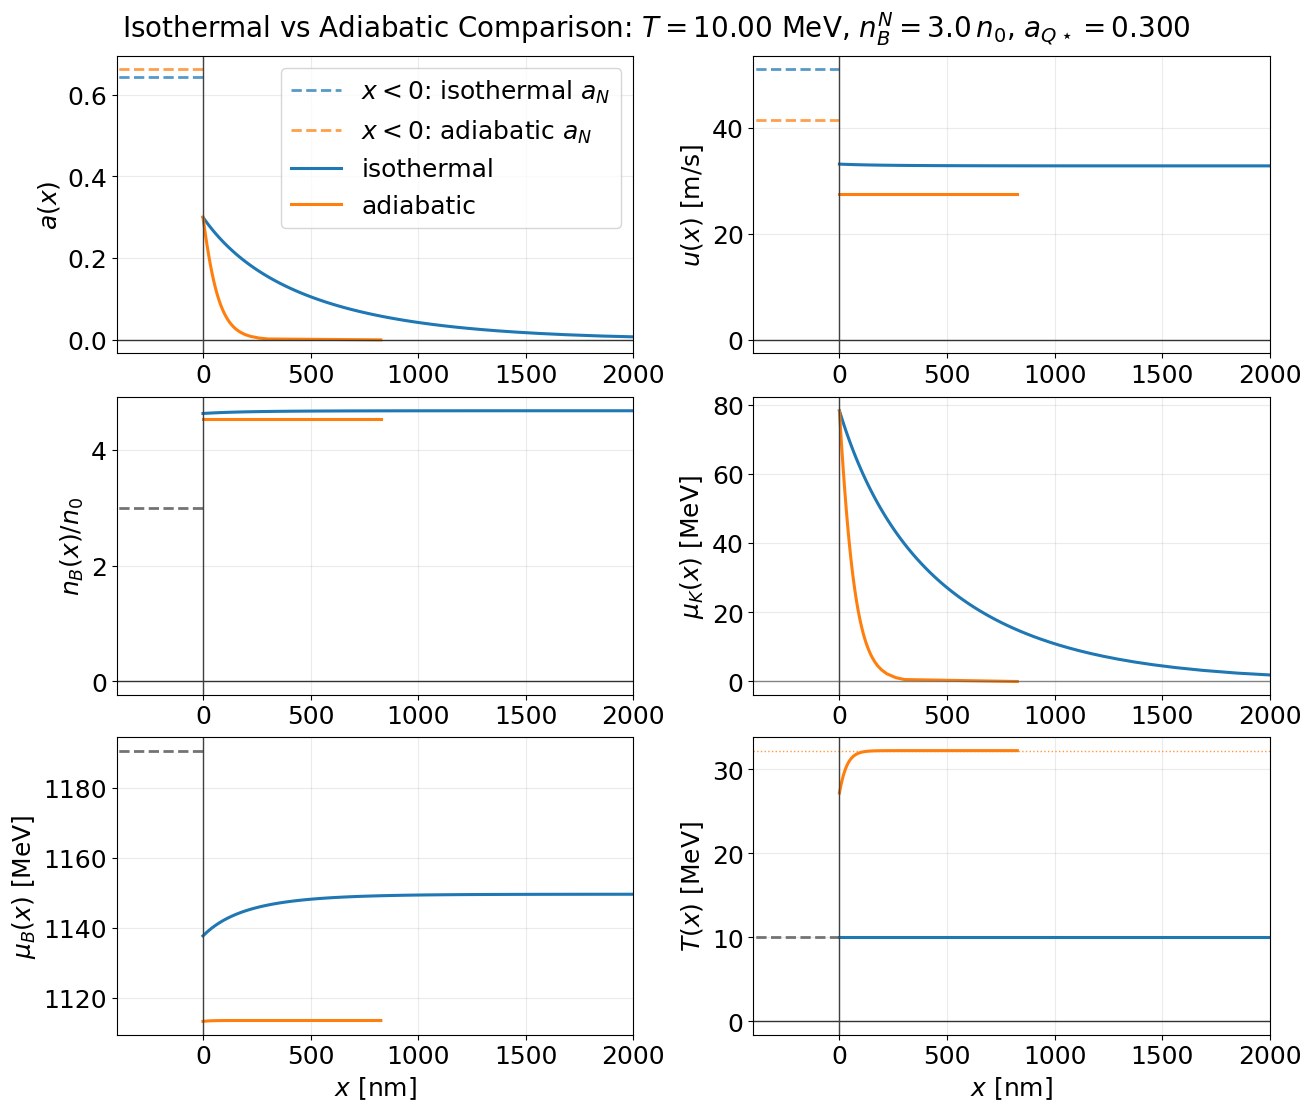

In [2]:
# VISUALIZE_ISOTHERMAL_ADIABATIC_COMPARISON
# Overlay the isothermal and adiabatic profiles for the shared-input trial.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import _solve_scalar_root, nB_NM

required_compare_names = [
    'res_isothermal_compare_trial',
    'res_adiabatic_compare_trial',
    'T_compare_trial',
    'nB_N_compare_trial',
    'aQstar_compare_trial',
    'n0',
]
missing_compare_names = [name for name in required_compare_names if name not in globals()]
if missing_compare_names:
    raise RuntimeError(
        'Run the COMPARE_ISOTHERMAL_ADIABATIC_TRIAL cell first. Missing names: '
        + ', '.join(missing_compare_names)
    )

x_iso_nm = np.asarray(res_isothermal_compare_trial['x'], dtype=float) * const.MeV_fm / 1.0e6
x_adi_nm = np.asarray(res_adiabatic_compare_trial['x'], dtype=float) * const.MeV_fm / 1.0e6

a_iso = np.asarray(res_isothermal_compare_trial['a'], dtype=float)
a_adi = np.asarray(res_adiabatic_compare_trial['a'], dtype=float)
u_iso_ms = np.asarray(res_isothermal_compare_trial['u'], dtype=float) * const.m_per_sec
u_adi_ms = np.asarray(res_adiabatic_compare_trial['u'], dtype=float) * const.m_per_sec
nB_iso_over_n0 = np.asarray(res_isothermal_compare_trial['nB'], dtype=float) / n0
nB_adi_over_n0 = np.asarray(res_adiabatic_compare_trial['nB'], dtype=float) / n0
muK_iso = np.asarray(res_isothermal_compare_trial['muK'], dtype=float)
muK_adi = np.asarray(res_adiabatic_compare_trial['muK'], dtype=float)
muB_iso = np.asarray(res_isothermal_compare_trial['muB'], dtype=float)
muB_adi = np.asarray(res_adiabatic_compare_trial['muB'], dtype=float)
T_iso = np.full_like(x_iso_nm, float(T_compare_trial), dtype=float)
T_adi = np.asarray(res_adiabatic_compare_trial['T_profile'], dtype=float)
q_iso = np.asarray(res_isothermal_compare_trial.get('q', np.nan), dtype=float)
w_adi = np.asarray(res_adiabatic_compare_trial.get('w', np.nan), dtype=float)

positive_extent_nm = 1.0e-3
if len(x_iso_nm):
    positive_extent_nm = max(positive_extent_nm, float(np.nanmax(x_iso_nm)))
if len(x_adi_nm):
    positive_extent_nm = max(positive_extent_nm, float(np.nanmax(x_adi_nm)))
left_extent_nm = max(0.12 * positive_extent_nm, 500.0)
x_left_nm = np.linspace(-left_extent_nm, 0.0, 120)
a_left_iso = np.full_like(x_left_nm, float(res_isothermal_compare_trial.get('a_N', np.nan)), dtype=float)
a_left_adi = np.full_like(x_left_nm, float(res_adiabatic_compare_trial.get('a_N', np.nan)), dtype=float)
u_left_iso_ms = np.full_like(
    x_left_nm,
    float(res_isothermal_compare_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
u_left_adi_ms = np.full_like(
    x_left_nm,
    float(res_adiabatic_compare_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
muB_N_compare_trial = float(
    _solve_scalar_root(
        lambda muB: nB_NM(muB, T_compare_trial) - nB_N_compare_trial,
        1050.0,
    )
)
muB_left = np.full_like(x_left_nm, muB_N_compare_trial, dtype=float)
nB_left_over_n0 = np.full_like(x_left_nm, float(nB_N_compare_trial / n0), dtype=float)
T_left = np.full_like(x_left_nm, float(T_compare_trial), dtype=float)
x_right_limit_nm = max(1.02 * positive_extent_nm, 500.0)
x_left_limit_nm = -min(left_extent_nm, 0.2 * x_right_limit_nm)

TitleFont = 20
LabelFont = 18
TickFont = 18
LegendFont = 18

fig, axes = plt.subplots(3, 2, figsize=(13.0, 11.0), constrained_layout=True)

axes[0, 0].plot(x_left_nm, a_left_iso, lw=2.0, ls='--', color='C0', alpha=0.75, label=r'$x<0$: isothermal $a_N$')
axes[0, 0].plot(x_left_nm, a_left_adi, lw=2.0, ls='--', color='C1', alpha=0.75, label=r'$x<0$: adiabatic $a_N$')
axes[0, 0].plot(x_iso_nm, a_iso, lw=2.2, color='C0', label='isothermal')
axes[0, 0].plot(x_adi_nm, a_adi, lw=2.2, color='C1', label='adiabatic')
axes[0, 0].axhline(0.0, color='0.20', lw=1.0)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0, 0].legend(fontsize=LegendFont)

axes[0, 1].plot(x_left_nm, u_left_iso_ms, lw=2.0, ls='--', color='C0', alpha=0.75, label=r'$x<0$: isothermal $u_N$')
axes[0, 1].plot(x_left_nm, u_left_adi_ms, lw=2.0, ls='--', color='C1', alpha=0.75, label=r'$x<0$: adiabatic $u_N$')
axes[0, 1].plot(x_iso_nm, u_iso_ms, lw=2.2, color='C0', label='isothermal')
axes[0, 1].plot(x_adi_nm, u_adi_ms, lw=2.2, color='C1', label='adiabatic')
axes[0, 1].axhline(0.0, color='0.20', lw=1.0)
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
#axes[0, 1].legend(fontsize=LegendFont)

axes[1, 0].plot(x_left_nm, nB_left_over_n0, lw=2.0, ls='--', color='0.45', label=r'$x<0$: upstream $n_B/n_0$')
axes[1, 0].plot(x_iso_nm, nB_iso_over_n0, lw=2.2, color='C0', label='isothermal')
axes[1, 0].plot(x_adi_nm, nB_adi_over_n0, lw=2.2, color='C1', label='adiabatic')
axes[1, 0].axhline(0.0, color='0.20', lw=1.0)
axes[1, 0].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)
#axes[1, 0].legend(fontsize=LegendFont)

axes[1, 1].plot(x_iso_nm, muK_iso, lw=2.2, color='C0', label='isothermal')
axes[1, 1].plot(x_adi_nm, muK_adi, lw=2.2, color='C1', label='adiabatic')
axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)
#axes[1, 1].legend(fontsize=LegendFont)

axes[2, 0].plot(x_left_nm, muB_left, lw=2.0, ls='--', color='0.45', label=r'$x<0$: upstream $\mu_B$')
axes[2, 0].plot(x_iso_nm, muB_iso, lw=2.2, color='C0', label='isothermal')
axes[2, 0].plot(x_adi_nm, muB_adi, lw=2.2, color='C1', label='adiabatic')
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)
axes[2, 0].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
#axes[2, 0].legend(fontsize=LegendFont)

axes[2, 1].plot(x_left_nm, T_left, lw=2.0, ls='--', color='0.45', label=r'$x<0$: upstream $T$')
axes[2, 1].plot(x_iso_nm, T_iso, lw=2.2, color='C0', label='isothermal')
axes[2, 1].plot(x_adi_nm, T_adi, lw=2.2, color='C1', label='adiabatic')
T_Q = res_adiabatic_compare_trial.get('T_Q', np.nan)
axes[2, 1].axhline(T_Q, color='C1', lw=1.0, ls=':', alpha=0.8, label=rf'$T_Q={T_Q:.2f}$ MeV')
axes[2, 1].axhline(0.0, color='0.20', lw=1.0)
axes[2, 1].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)
axes[2, 1].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
#axes[2, 1].legend(fontsize=LegendFont)

for ax in axes.flat:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(-400, 2000)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig.suptitle(
    rf'Isothermal vs Adiabatic Comparison: $T={T_compare_trial:.2f}$ MeV, '
    rf'$n_{{B}}^{{N}}={nB_N_compare_trial / n0:.1f}\,n_0$, '
    rf'$a_{{Q\star}}={aQstar_compare_trial:.3f}$',
    fontsize=TitleFont,
)

print(
    f'isothermal q range: [{np.nanmin(q_iso):.6g}, {np.nanmax(q_iso):.6g}]'
)
print(
    f'adiabatic w range: [{np.nanmin(w_adi):.6g}, {np.nanmax(w_adi):.6g}]'
)

plt.savefig("isothermal_vs_adiabatic.pdf", bbox_inches="tight", dpi=300)

plt.show()


isothermal q range: [-5.95133e-07, -1.93941e-13]
adiabatic w range: [1.686, 6.91915]


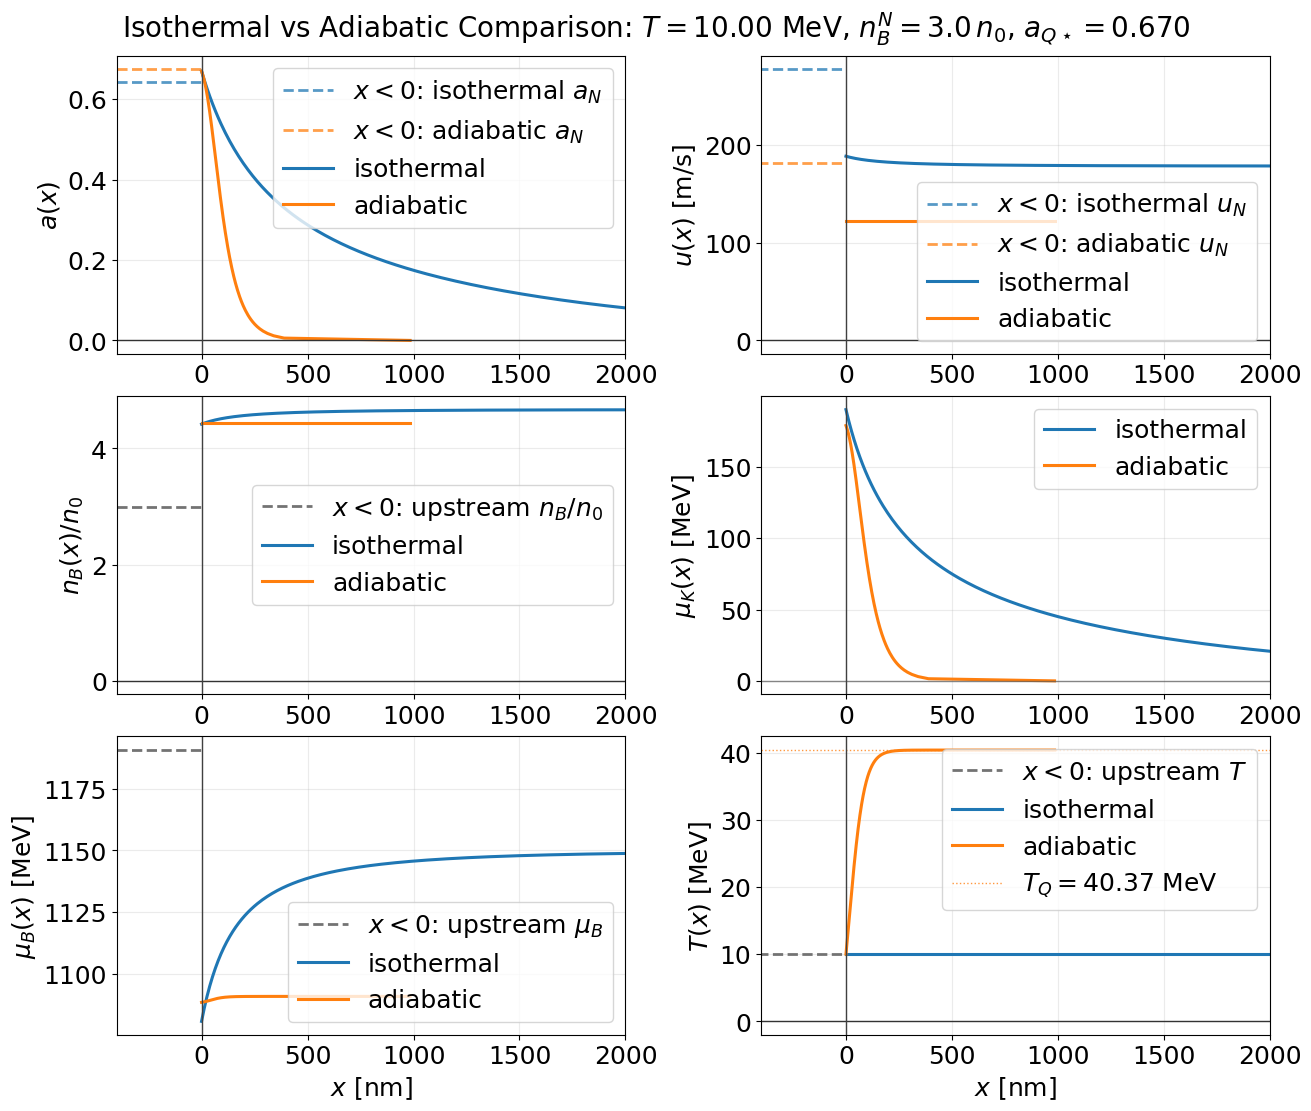

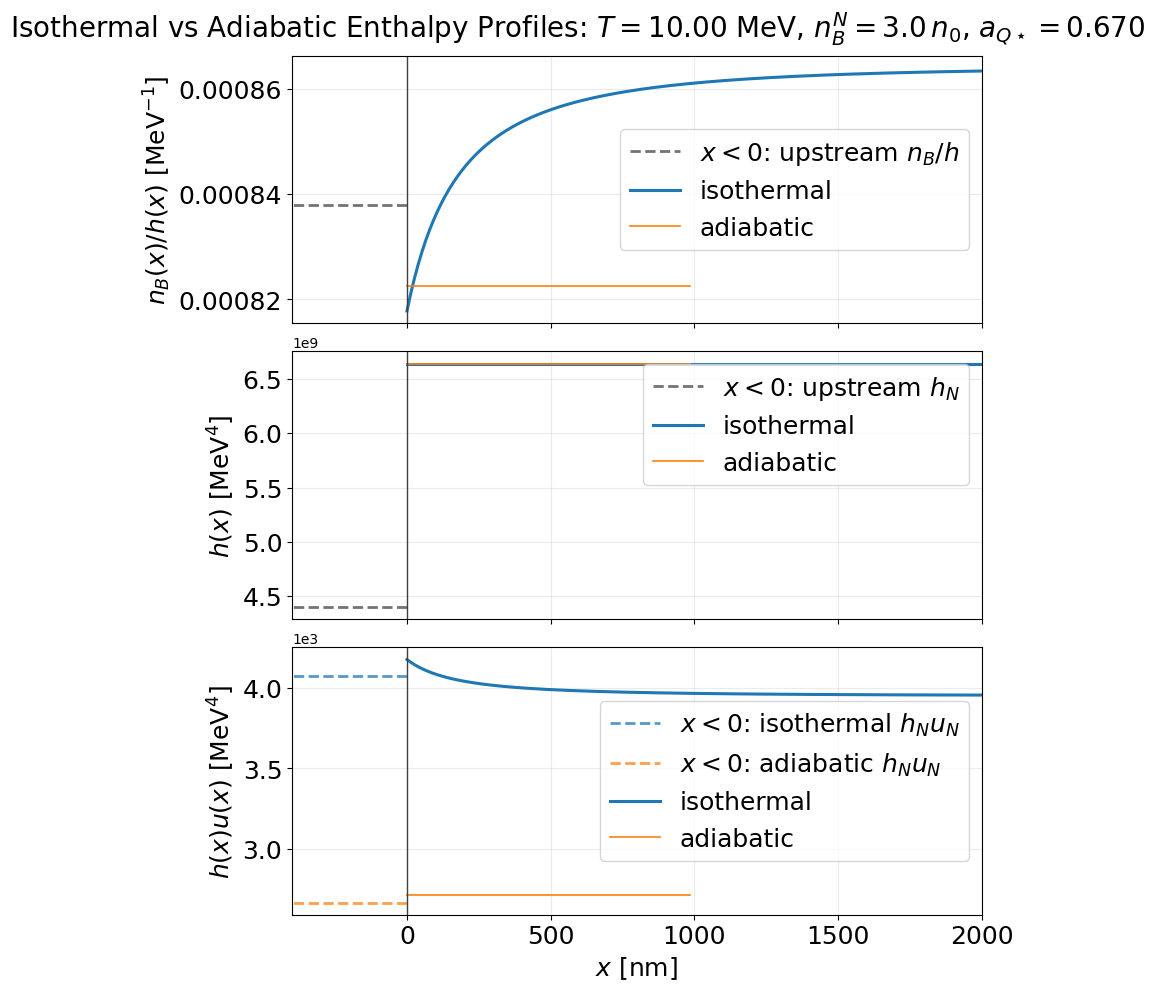

In [13]:
# VISUALIZE_ISOTHERMAL_ADIABATIC_COMPARISON
# Overlay the isothermal and adiabatic profiles for the shared-input trial.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import _solve_scalar_root, nB_NM

required_compare_names = [
    'res_isothermal_compare_trial',
    'res_adiabatic_compare_trial',
    'T_compare_trial',
    'nB_N_compare_trial',
    'aQstar_compare_trial',
    'n0',
]
missing_compare_names = [name for name in required_compare_names if name not in globals()]
if missing_compare_names:
    raise RuntimeError(
        'Run the COMPARE_ISOTHERMAL_ADIABATIC_TRIAL cell first. Missing names: '
        + ', '.join(missing_compare_names)
    )

x_iso_nm = np.asarray(res_isothermal_compare_trial['x'], dtype=float) * const.MeV_fm / 1.0e6
x_adi_nm = np.asarray(res_adiabatic_compare_trial['x'], dtype=float) * const.MeV_fm / 1.0e6

a_iso = np.asarray(res_isothermal_compare_trial['a'], dtype=float)
a_adi = np.asarray(res_adiabatic_compare_trial['a'], dtype=float)
u_iso_ms = np.asarray(res_isothermal_compare_trial['u'], dtype=float) * const.m_per_sec
u_adi_ms = np.asarray(res_adiabatic_compare_trial['u'], dtype=float) * const.m_per_sec
nB_iso_over_n0 = np.asarray(res_isothermal_compare_trial['nB'], dtype=float) / n0
nB_adi_over_n0 = np.asarray(res_adiabatic_compare_trial['nB'], dtype=float) / n0
muK_iso = np.asarray(res_isothermal_compare_trial['muK'], dtype=float)
muK_adi = np.asarray(res_adiabatic_compare_trial['muK'], dtype=float)
muB_iso = np.asarray(res_isothermal_compare_trial['muB'], dtype=float)
muB_adi = np.asarray(res_adiabatic_compare_trial['muB'], dtype=float)
T_iso = np.full_like(x_iso_nm, float(T_compare_trial), dtype=float)
T_adi = np.asarray(res_adiabatic_compare_trial['T_profile'], dtype=float)
q_iso = np.asarray(res_isothermal_compare_trial.get('q', np.nan), dtype=float)
w_adi = np.asarray(res_adiabatic_compare_trial.get('w', np.nan), dtype=float)

positive_extent_nm = 1.0e-3
if len(x_iso_nm):
    positive_extent_nm = max(positive_extent_nm, float(np.nanmax(x_iso_nm)))
if len(x_adi_nm):
    positive_extent_nm = max(positive_extent_nm, float(np.nanmax(x_adi_nm)))
left_extent_nm = max(0.12 * positive_extent_nm, 500.0)
x_left_nm = np.linspace(-left_extent_nm, 0.0, 120)
a_left_iso = np.full_like(x_left_nm, float(res_isothermal_compare_trial.get('a_N', np.nan)), dtype=float)
a_left_adi = np.full_like(x_left_nm, float(res_adiabatic_compare_trial.get('a_N', np.nan)), dtype=float)
u_left_iso_ms = np.full_like(
    x_left_nm,
    float(res_isothermal_compare_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
u_left_adi_ms = np.full_like(
    x_left_nm,
    float(res_adiabatic_compare_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
muB_N_compare_trial = float(
    _solve_scalar_root(
        lambda muB: nB_NM(muB, T_compare_trial) - nB_N_compare_trial,
        1050.0,
    )
)
muB_left = np.full_like(x_left_nm, muB_N_compare_trial, dtype=float)
nB_left_over_n0 = np.full_like(x_left_nm, float(nB_N_compare_trial / n0), dtype=float)
T_left = np.full_like(x_left_nm, float(T_compare_trial), dtype=float)
x_right_limit_nm = max(1.02 * positive_extent_nm, 500.0)
x_left_limit_nm = -min(left_extent_nm, 0.2 * x_right_limit_nm)

TitleFont = 20
LabelFont = 18
TickFont = 18
LegendFont = 18

fig, axes = plt.subplots(3, 2, figsize=(13.0, 11.0), constrained_layout=True)

axes[0, 0].plot(x_left_nm, a_left_iso, lw=2.0, ls='--', color='C0', alpha=0.75, label=r'$x<0$: isothermal $a_N$')
axes[0, 0].plot(x_left_nm, a_left_adi, lw=2.0, ls='--', color='C1', alpha=0.75, label=r'$x<0$: adiabatic $a_N$')
axes[0, 0].plot(x_iso_nm, a_iso, lw=2.2, color='C0', label='isothermal')
axes[0, 0].plot(x_adi_nm, a_adi, lw=2.2, color='C1', label='adiabatic')
axes[0, 0].axhline(0.0, color='0.20', lw=1.0)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0, 0].legend(fontsize=LegendFont)

axes[0, 1].plot(x_left_nm, u_left_iso_ms, lw=2.0, ls='--', color='C0', alpha=0.75, label=r'$x<0$: isothermal $u_N$')
axes[0, 1].plot(x_left_nm, u_left_adi_ms, lw=2.0, ls='--', color='C1', alpha=0.75, label=r'$x<0$: adiabatic $u_N$')
axes[0, 1].plot(x_iso_nm, u_iso_ms, lw=2.2, color='C0', label='isothermal')
axes[0, 1].plot(x_adi_nm, u_adi_ms, lw=2.2, color='C1', label='adiabatic')
axes[0, 1].axhline(0.0, color='0.20', lw=1.0)
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
axes[0, 1].legend(fontsize=LegendFont)

axes[1, 0].plot(x_left_nm, nB_left_over_n0, lw=2.0, ls='--', color='0.45', label=r'$x<0$: upstream $n_B/n_0$')
axes[1, 0].plot(x_iso_nm, nB_iso_over_n0, lw=2.2, color='C0', label='isothermal')
axes[1, 0].plot(x_adi_nm, nB_adi_over_n0, lw=2.2, color='C1', label='adiabatic')
axes[1, 0].axhline(0.0, color='0.20', lw=1.0)
axes[1, 0].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)
axes[1, 0].legend(fontsize=LegendFont)

axes[1, 1].plot(x_iso_nm, muK_iso, lw=2.2, color='C0', label='isothermal')
axes[1, 1].plot(x_adi_nm, muK_adi, lw=2.2, color='C1', label='adiabatic')
axes[1, 1].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 1].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)
axes[1, 1].legend(fontsize=LegendFont)

axes[2, 0].plot(x_left_nm, muB_left, lw=2.0, ls='--', color='0.45', label=r'$x<0$: upstream $\mu_B$')
axes[2, 0].plot(x_iso_nm, muB_iso, lw=2.2, color='C0', label='isothermal')
axes[2, 0].plot(x_adi_nm, muB_adi, lw=2.2, color='C1', label='adiabatic')
axes[2, 0].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)
axes[2, 0].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
axes[2, 0].legend(fontsize=LegendFont)

axes[2, 1].plot(x_left_nm, T_left, lw=2.0, ls='--', color='0.45', label=r'$x<0$: upstream $T$')
axes[2, 1].plot(x_iso_nm, T_iso, lw=2.2, color='C0', label='isothermal')
axes[2, 1].plot(x_adi_nm, T_adi, lw=2.2, color='C1', label='adiabatic')
T_Q = res_adiabatic_compare_trial.get('T_Q', np.nan)
axes[2, 1].axhline(T_Q, color='C1', lw=1.0, ls=':', alpha=0.8, label=rf'$T_Q={T_Q:.2f}$ MeV')
axes[2, 1].axhline(0.0, color='0.20', lw=1.0)
axes[2, 1].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)
axes[2, 1].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
axes[2, 1].legend(fontsize=LegendFont)

for ax in axes.flat:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(-400, 2000)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig.suptitle(
    rf'Isothermal vs Adiabatic Comparison: $T={T_compare_trial:.2f}$ MeV, '
    rf'$n_{{B}}^{{N}}={nB_N_compare_trial / n0:.1f}\,n_0$, '
    rf'$a_{{Q\star}}={aQstar_compare_trial:.3f}$',
    fontsize=TitleFont,
)

print(
    f'isothermal q range: [{np.nanmin(q_iso):.6g}, {np.nanmax(q_iso):.6g}]'
)
print(
    f'adiabatic w range: [{np.nanmin(w_adi):.6g}, {np.nanmax(w_adi):.6g}]'
)

plt.savefig("isothermal_vs_adiabatic.pdf", bbox_inches="tight", dpi=300)

plt.show()


# VISUALIZE_ISOTHERMAL_ADIABATIC_ENTHALPY_PROFILES
# Add nB(x)/h(x), h(x), and h(x)u(x) profiles over x<0 and x>0.

from RMFsolver.phase_velocity import PNM_n, edensNM_n, _quark_thermo_state

required_enthalpy_names = [
    'B14_compare_trial',
    'ms_compare_trial',
]
missing_enthalpy_names = [name for name in required_enthalpy_names if name not in globals()]
if missing_enthalpy_names:
    raise RuntimeError(
        'Run the COMPARE_ISOTHERMAL_ADIABATIC_TRIAL cell first. Missing names: '
        + ', '.join(missing_enthalpy_names)
    )


def _comparison_enthalpy_profile(result, T_values):
    muB_values = np.asarray(result['muB'], dtype=float)
    muK_values = np.asarray(result['muK'], dtype=float)
    nB_values = np.asarray(result['nB'], dtype=float)
    T_values = np.asarray(T_values, dtype=float)
    if T_values.ndim == 0:
        T_values = np.full_like(muB_values, float(T_values), dtype=float)
    if T_values.shape != muB_values.shape:
        raise RuntimeError('Temperature profile shape does not match muB profile shape')

    h_values = np.empty_like(muB_values)
    jB_value = float(result['jB'])
    for i, (muB_value, muK_value, T_value) in enumerate(zip(muB_values, muK_values, T_values)):
        h_values[i] = _quark_thermo_state(
            muB_value,
            muK_value,
            B14_compare_trial,
            T_value,
            jB_value,
            ms=ms_compare_trial,
        )['h']
    return h_values, nB_values / h_values


h_N_compare_trial = float(
    PNM_n(nB_N_compare_trial, T_compare_trial)
    + edensNM_n(nB_N_compare_trial, T_compare_trial)
)
nB_over_h_left = np.full_like(
    x_left_nm,
    float(nB_N_compare_trial / h_N_compare_trial),
    dtype=float,
)
h_left = np.full_like(x_left_nm, h_N_compare_trial, dtype=float)
h_u_left_iso = np.full_like(
    x_left_nm,
    h_N_compare_trial * float(res_isothermal_compare_trial['u_N']),
    dtype=float,
)
h_u_left_adi = np.full_like(
    x_left_nm,
    h_N_compare_trial * float(res_adiabatic_compare_trial['u_N']),
    dtype=float,
)

h_iso, nB_over_h_iso = _comparison_enthalpy_profile(
    res_isothermal_compare_trial,
    T_compare_trial,
)
h_adi, nB_over_h_adi = _comparison_enthalpy_profile(
    res_adiabatic_compare_trial,
    T_adi,
)
h_u_iso = h_iso * np.asarray(res_isothermal_compare_trial['u'], dtype=float)
h_u_adi = h_adi * np.asarray(res_adiabatic_compare_trial['u'], dtype=float)

fig_h, axes_h = plt.subplots(3, 1, figsize=(8.8, 9.8), sharex=True, constrained_layout=True)

axes_h[0].plot(
    x_left_nm,
    nB_over_h_left,
    lw=2.0,
    ls='--',
    color='0.45',
    label=r'$x<0$: upstream $n_B/h$',
)
axes_h[0].plot(x_iso_nm, nB_over_h_iso, lw=2.2, color='C0', label='isothermal')
axes_h[0].plot(x_adi_nm, nB_over_h_adi, lw=1.2, color='C1', label='adiabatic')
axes_h[0].set_ylabel(r'$n_B(x)/h(x)$ [MeV$^{-1}$]', fontsize=LabelFont)
axes_h[0].legend(fontsize=LegendFont)

axes_h[1].plot(
    x_left_nm,
    h_left,
    lw=2.0,
    ls='--',
    color='0.45',
    label=r'$x<0$: upstream $h_N$',
)
axes_h[1].plot(x_iso_nm, h_iso, lw=2.2, color='C0', label='isothermal')
axes_h[1].plot(x_adi_nm, h_adi, lw=1.2, color='C1', label='adiabatic')
axes_h[1].set_ylabel(r'$h(x)$ [MeV$^4$]', fontsize=LabelFont)
axes_h[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
axes_h[1].legend(fontsize=LegendFont)

axes_h[2].plot(
    x_left_nm,
    h_u_left_iso,
    lw=2.0,
    ls='--',
    color='C0',
    alpha=0.75,
    label=r'$x<0$: isothermal $h_Nu_N$',
)
axes_h[2].plot(
    x_left_nm,
    h_u_left_adi,
    lw=2.0,
    ls='--',
    color='C1',
    alpha=0.75,
    label=r'$x<0$: adiabatic $h_Nu_N$',
)
axes_h[2].plot(x_iso_nm, h_u_iso, lw=2.2, color='C0', label='isothermal')
axes_h[2].plot(x_adi_nm, h_u_adi, lw=1.2, color='C1', label='adiabatic')
axes_h[2].set_ylabel(r'$h(x)u(x)$ [MeV$^4$]', fontsize=LabelFont)
axes_h[2].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
axes_h[2].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
axes_h[2].legend(fontsize=LegendFont)

for ax in axes_h:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(-400, 2000)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig_h.suptitle(
    rf'Isothermal vs Adiabatic Enthalpy Profiles: $T={T_compare_trial:.2f}$ MeV, '
    rf'$n_{{B}}^{{N}}={nB_N_compare_trial / n0:.1f}\,n_0$, '
    rf'$a_{{Q\star}}={aQstar_compare_trial:.3f}$',
    fontsize=TitleFont,
)

plt.savefig("isothermal_vs_adiabatic_enthalpy_profiles.pdf", bbox_inches="tight", dpi=300)

plt.show()


In [4]:
T_Q

20.018579438659444

## Hugoniot/CJ Scan: calculation cell

This cell scans several input values of  $a_{Q\star}$  for both the isothermal and adiabatic front solvers.

What it does:
- Runs the front solver for each chosen  $a_{Q\star}$ .
- Reconstructs the fixed-interface-temperature Taub/Hugoniot branch on the quark side.
- Estimates a CJ-like point by comparing the Hugoniot slope with the Rayleigh slope  $j_B^2$ .
- Stores all results in  hugoniot_scan_data  for the next visualization cell.

Notes:
- This cell can take a while because it runs the nonlinear front solvers multiple times.
- The scan inputs are controlled near the top of the code cell, especially  aQstar_hugoniot_examples .
- Nothing is plotted here; this cell only computes and stores diagnostics.


In [6]:
# HUGONIOT_RAYLEIGH_AQSTAR_SCAN_CALC
# Scan several aQstar values, reconstruct the fixed-interface-temperature
# Taub/Hugoniot curve, and estimate CJ-like tangency points.

import numpy as np
from scipy.optimize import brentq

import RMFsolver.constants as const
from RMFsolver.phase_velocity import (
    PNM_n,
    edensNM_n,
    solve_front_adiabatic,
    solve_front_isothermal,
)
from RMFsolver.SQMsolver import PQM, edensQM, nB_QM

required_hugoniot_names = [
    'T_compare_trial',
    'nB_N_compare_trial',
    'B14_compare_trial',
    'ms_compare_trial',
    'aQstar_compare_trial',
    'tail_eps_compare_trial',
    'n_mesh_compare_trial',
    'tol_compare_trial',
    'max_nodes_compare_trial',
    'jB_guess_compare_trial',
    'jB_bounds_compare_trial',
    'res_isothermal_compare_trial',
    'res_adiabatic_compare_trial',
]
missing_hugoniot_names = [name for name in required_hugoniot_names if name not in globals()]
if missing_hugoniot_names:
    raise RuntimeError(
        'Run the COMPARE_ISOTHERMAL_ADIABATIC_TRIAL cell first. Missing names: '
        + ', '.join(missing_hugoniot_names)
    )

# Editable scan controls.
aQstar_hugoniot_examples = [0.05, 0.15, 0.30, 0.45]
muK_curve_samples = 81
muB_bracket = (850.0, 1500.0)
muB_bracket_samples = 320

T_star = float(T_compare_trial)
nB_N_upstream = float(nB_N_compare_trial)
B14_star = float(B14_compare_trial)
ms_star = float(ms_compare_trial)

P_N = float(PNM_n(nB_N_upstream, T_star))
e_N = float(edensNM_n(nB_N_upstream, T_star))
h_N = float(P_N + e_N)
X_N = float(h_N / (nB_N_upstream ** 2))
muN_sq = float((h_N / nB_N_upstream) ** 2)


def quark_state_fixed_T(muB, muK):
    P = float(PQM(muB, muK, B14_star, T_star, ms=ms_star))
    e = float(edensQM(muB, muK, B14_star, T_star, ms=ms_star, include_em=False))
    nB = float(nB_QM(muB, muK, B14_star, T_star, ms=ms_star))
    if (not np.isfinite(P)) or (not np.isfinite(e)) or (not np.isfinite(nB)) or nB <= 0.0:
        raise RuntimeError('Non-physical fixed-T quark state encountered')
    h = float(P + e)
    X = float(h / (nB ** 2))
    mu_over_n = float(h / nB)
    return {
        'P': P,
        'e': e,
        'nB': nB,
        'h': h,
        'X': X,
        'mu_over_n': mu_over_n,
    }


def taub_residual(muB, muK):
    state = quark_state_fixed_T(muB, muK)
    return float(
        state['mu_over_n'] ** 2
        - muN_sq
        - (state['P'] - P_N) * (h_N / (nB_N_upstream ** 2) + state['h'] / (state['nB'] ** 2))
    )


def taub_root_candidates(muK, muB_min, muB_max, num_points):
    mu_grid = np.linspace(muB_min, muB_max, num_points)
    residual_grid = np.full_like(mu_grid, np.nan, dtype=float)
    for idx, muB_val in enumerate(mu_grid):
        try:
            residual_grid[idx] = taub_residual(float(muB_val), float(muK))
        except Exception:
            residual_grid[idx] = np.nan

    candidates = []
    for idx in range(len(mu_grid) - 1):
        left = residual_grid[idx]
        right = residual_grid[idx + 1]
        if not (np.isfinite(left) and np.isfinite(right)):
            continue
        if abs(left) < 1.0e-10:
            candidates.append(float(mu_grid[idx]))
            continue
        if left * right > 0.0:
            continue
        try:
            root = brentq(
                lambda trial_muB: taub_residual(float(trial_muB), float(muK)),
                float(mu_grid[idx]),
                float(mu_grid[idx + 1]),
                xtol=1.0e-10,
                rtol=1.0e-10,
                maxiter=200,
            )
        except ValueError:
            continue
        candidates.append(float(root))

    deduped = []
    for root in candidates:
        if not any(abs(root - old) <= 1.0e-6 * max(1.0, abs(root), abs(old)) for old in deduped):
            deduped.append(root)
    return deduped


def solve_taub_branch(muK_values, muB_seed):
    muB_out = np.full_like(muK_values, np.nan, dtype=float)
    P_out = np.full_like(muK_values, np.nan, dtype=float)
    X_out = np.full_like(muK_values, np.nan, dtype=float)
    prev_root = float(muB_seed)

    for idx, muK_val in enumerate(muK_values):
        roots = taub_root_candidates(
            muK=float(muK_val),
            muB_min=float(muB_bracket[0]),
            muB_max=float(muB_bracket[1]),
            num_points=int(muB_bracket_samples),
        )
        if not roots:
            continue
        root = min(roots, key=lambda candidate: abs(candidate - prev_root))
        prev_root = float(root)
        state = quark_state_fixed_T(prev_root, float(muK_val))
        muB_out[idx] = prev_root
        P_out[idx] = state['P']
        X_out[idx] = state['X']

    return muB_out, P_out, X_out


def summarize_result(result):
    qstar_state = quark_state_fixed_T(
        float(result['muB_Qstar']),
        float(result['muK_Qstar']),
    )
    return {
        'success': bool(result.get('success', False)),
        'aQstar': float(result['aQstar']),
        'jB': float(result['jB']),
        'Pi': float(result['Pi']),
        'muK_Qstar': float(result['muK_Qstar']),
        'muB_Qstar': float(result['muB_Qstar']),
        'X_Qstar': float(qstar_state['X']),
        'P_Qstar': float(qstar_state['P']),
    }


def run_scan_result(solver_name, aQstar_value):
    if abs(float(aQstar_value) - float(aQstar_compare_trial)) <= 1.0e-12:
        if solver_name == 'isothermal':
            return dict(res_isothermal_compare_trial)
        if solver_name == 'adiabatic':
            return dict(res_adiabatic_compare_trial)
        raise ValueError(f'Unknown solver name: {solver_name}')

    common_kwargs = dict(
        T=T_compare_trial,
        nB_N=nB_N_compare_trial,
        B_one_forth=B14_compare_trial,
        aQstar=float(aQstar_value),
        ms=ms_compare_trial,
        tail_eps=tail_eps_compare_trial,
        n_mesh=n_mesh_compare_trial,
        tol_bvp=tol_compare_trial,
        max_nodes=max_nodes_compare_trial,
        jB_guess=jB_guess_compare_trial,
        jB_bounds=jB_bounds_compare_trial,
        return_profile=False,
        verb=False,
    )
    if solver_name == 'isothermal':
        common_kwargs['kappa_factor'] = kappa_factor_compare_trial
        return solve_front_isothermal(**common_kwargs)
    if solver_name == 'adiabatic':
        common_kwargs['TQ_guess'] = TQ_guess_compare_trial
        return solve_front_adiabatic(**common_kwargs)
    raise ValueError(f'Unknown solver name: {solver_name}')


scan_results = {
    'isothermal': [],
    'adiabatic': [],
}
for solver_name in scan_results:
    for aQstar_value in aQstar_hugoniot_examples:
        result = run_scan_result(solver_name, aQstar_value)
        result = dict(result)
        result['solver_name'] = solver_name
        scan_results[solver_name].append(result)

successful_scan_results = []
for solver_results in scan_results.values():
    for result in solver_results:
        if bool(result.get('success')):
            successful_scan_results.append(result)

if not successful_scan_results:
    raise RuntimeError('No successful Hugoniot/Rayleigh scan results were produced')

muK_curve_max = max(
    40.0,
    1.20 * max(float(result['muK_Qstar']) for result in successful_scan_results),
)
muK_curve = np.linspace(0.0, muK_curve_max, int(muK_curve_samples))
muB_seed_curve = float(
    res_adiabatic_compare_trial.get(
        'muB_Q',
        res_isothermal_compare_trial.get('muB_Q', 1100.0),
    )
)
muB_curve, P_curve, X_curve = solve_taub_branch(muK_curve, muB_seed=muB_seed_curve)

valid_curve_mask = np.isfinite(muB_curve) & np.isfinite(P_curve) & np.isfinite(X_curve)
if np.count_nonzero(valid_curve_mask) < 5:
    raise RuntimeError('Fixed-T Taub/Hugoniot branch construction produced too few valid points')

muK_curve_valid = muK_curve[valid_curve_mask]
muB_curve_valid = muB_curve[valid_curve_mask]
P_curve_valid = P_curve[valid_curve_mask]
X_curve_valid = X_curve[valid_curve_mask]
dP_dmuK = np.gradient(P_curve_valid, muK_curve_valid)
dX_dmuK = np.gradient(X_curve_valid, muK_curve_valid)
with np.errstate(divide='ignore', invalid='ignore'):
    hugoniot_slope = dP_dmuK / dX_dmuK

scan_summary = {
    'isothermal': [],
    'adiabatic': [],
}
for solver_name, solver_results in scan_results.items():
    for result in solver_results:
        entry = {
            'solver_name': solver_name,
            'aQstar': float(result['aQstar']),
            'success': bool(result.get('success', False)),
            'message': str(result.get('message', '')),
        }
        if entry['success']:
            entry.update(summarize_result(result))
            slope_gap = np.abs(hugoniot_slope + entry['jB'] ** 2)
            finite_gap_mask = np.isfinite(slope_gap)
            if np.count_nonzero(finite_gap_mask) == 0:
                raise RuntimeError('Failed to estimate CJ tangency because the Hugoniot slope is non-finite everywhere')
            finite_indices = np.flatnonzero(finite_gap_mask)
            best_local_index = int(finite_indices[np.argmin(slope_gap[finite_gap_mask])])
            entry['muK_CJ_est'] = float(muK_curve_valid[best_local_index])
            entry['muB_CJ_est'] = float(muB_curve_valid[best_local_index])
            entry['X_CJ_est'] = float(X_curve_valid[best_local_index])
            entry['P_CJ_est'] = float(P_curve_valid[best_local_index])
            entry['slope_CJ_est'] = float(hugoniot_slope[best_local_index])
            if entry['muK_CJ_est'] > 0.0:
                entry['muK_fraction_of_CJ'] = float(entry['muK_Qstar'] / entry['muK_CJ_est'])
            else:
                entry['muK_fraction_of_CJ'] = np.nan
        scan_summary[solver_name].append(entry)

hugoniot_scan_data = {
    'aQstar_hugoniot_examples': list(aQstar_hugoniot_examples),
    'T_star': float(T_star),
    'nB_N_upstream': float(nB_N_upstream),
    'P_N': float(P_N),
    'e_N': float(e_N),
    'h_N': float(h_N),
    'X_N': float(X_N),
    'muK_curve_valid': np.asarray(muK_curve_valid, dtype=float),
    'muB_curve_valid': np.asarray(muB_curve_valid, dtype=float),
    'P_curve_valid': np.asarray(P_curve_valid, dtype=float),
    'X_curve_valid': np.asarray(X_curve_valid, dtype=float),
    'hugoniot_slope': np.asarray(hugoniot_slope, dtype=float),
    'scan_summary': scan_summary,
    'n0': float(n0),
}

for solver_name in ['isothermal', 'adiabatic']:
    print(f'\n{solver_name.upper()} scan summary:')
    for entry in scan_summary[solver_name]:
        if not entry['success']:
            print(f"  aQstar={entry['aQstar']:.3f}: solve failed -> {entry['message']}")
            continue
        print(
            f"  aQstar={entry['aQstar']:.3f}: "
            f"muK(Q*)={entry['muK_Qstar']:.6g} MeV, "
            f"muK_CJ_est={entry['muK_CJ_est']:.6g} MeV, "
            f"muK/muK_CJ={entry['muK_fraction_of_CJ']:.6g}, "
            f"jB={entry['jB']:.6g}"
        )


KeyboardInterrupt: 

## Hugoniot/CJ Scan: introduction and plot guide

The point of this analysis is to test whether increasing the input $a_{Q\star}$ pushes the post-boundary quark state $Q^*$ toward a **CJ-like state**.

### Short Hugoniot introduction

For a fixed upstream nuclear state $N$, the Taub relation defines a curve of downstream states that satisfy the relativistic jump conditions. In this notebook we reconstruct that curve on the quark side at fixed interface temperature $T_*$, so it serves as a **fixed-$T_*$ Hugoniot branch**.

The basic logic is:
- pick an input $a_{Q\star}$ and run the front solver,
- read off the solver-selected $Q^*$ state,
- estimate a CJ point on the same fixed-$T_*$ Hugoniot branch,
- compare $Q^*$ against that CJ estimate.

### What the three panels now show

- **Left:** direct comparison of $\mu_K(Q^*)$ against the estimated $\mu_K^{\rm CJ}$ as a function of the input $a_{Q\star}$.
- **Middle:** the main scalar diagnostic, $\mu_K(Q^*) / \mu_K^{\rm CJ}$. If this ratio approaches $1$, the selected state is moving toward CJ.
- **Right:** a secondary geometric check showing where the selected $Q^*$ states sit on the fixed-$T_*$ Hugoniot branch in $(\mu_K, \mu_B)$.

### Plot conventions

- **Blue** = isothermal solver.
- **Red** = adiabatic solver.
- **Circle / square** = solver-selected $Q^*$.
- **Dashed line with x-markers** = estimated CJ values for that same solver.

Optional local explainer: [http://127.0.0.1:8765/hugoniot_scan_explainer.html](http://127.0.0.1:8765/hugoniot_scan_explainer.html)


In [ ]:
from RMFsolver.